# Hausa Sentiment — Step 2: Classical baselines & experiments

**Goal**
1. Train simple baselines on AfriSenti Hausa
2. Compare word / char / word+char TF-IDF with linear classifiers
3. Select the best classical model using **dev_noleak** (not leaked dev)
4. Report **test** macro-F1 once (final numbers only)
5. Save the best model + experiment table for the report


## 0. Setup


In [1]:
!pip -q install scikit-learn joblib pandas numpy

from pathlib import Path
import json, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)
import joblib

required_files = [
    "afrisenti_hau_train.csv",
    "afrisenti_hau_dev_noleak.csv",
    "afrisenti_hau_test.csv",
]
candidate_roots = [
    Path("/content/hausa-sentiment"),  # Colab project layout
    Path("/content"),                  # Colab files uploaded flat
    Path.cwd(),                         # repository-root execution
    Path.cwd().parent,                  # execution from notebooks/
]
ROOT = None
PROC = None
for candidate_root in candidate_roots:
    candidate_proc = candidate_root / "data" / "processed"
    if all((candidate_proc / filename).exists() for filename in required_files):
        ROOT, PROC = candidate_root, candidate_proc
        break
    if all((candidate_root / filename).exists() for filename in required_files):
        ROOT, PROC = candidate_root, candidate_root
        break
if PROC is None:
    searched = "\n".join(f"- {root}" for root in candidate_roots)
    raise FileNotFoundError(
        "Could not find the required processed CSV files. Searched:\n" + searched
    )

MODELS = ROOT / "models"
RESULTS = ROOT / "results"
MODELS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

LABELS = ["positive", "neutral", "negative"]
print("ROOT =", ROOT)
print("PROC =", PROC)
print("Found processed files:", ", ".join(required_files))


ROOT = c:\Users\hp\Downloads\hausa-sentiment-v2\hausa-sentiment-app
PROC = c:\Users\hp\Downloads\hausa-sentiment-v2\hausa-sentiment-app\data\processed
Found processed files: afrisenti_hau_train.csv, afrisenti_hau_dev_noleak.csv, afrisenti_hau_test.csv


## 1. Load data


In [2]:
train = pd.read_csv(PROC / "afrisenti_hau_train.csv")
dev_noleak = pd.read_csv(PROC / "afrisenti_hau_dev_noleak.csv")
test = pd.read_csv(PROC / "afrisenti_hau_test.csv")

# Use bag-of-words view for classical models
X_train = train["text_bow"].fillna("").astype(str)
y_train = train["label_id"].astype(int)
X_dev = dev_noleak["text_bow"].fillna("").astype(str)
y_dev = dev_noleak["label_id"].astype(int)
X_test = test["text_bow"].fillna("").astype(str)
y_test = test["label_id"].astype(int)

print(len(X_train), len(X_dev), len(X_test))
print("label ids: 0=positive, 1=neutral, 2=negative")


14172 2462 5303
label ids: 0=positive, 1=neutral, 2=negative


## 2. Metrics helper

Primary metric: **macro-F1** (equal weight per class). Also track accuracy and per-class F1.


In [3]:
def eval_split(y_true, y_pred, name="split"):
    return {
        "split": name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted")),
        "f1_positive": float(f1_score(y_true, y_pred, labels=[0], average="macro")),
        "f1_neutral": float(f1_score(y_true, y_pred, labels=[1], average="macro")),
        "f1_negative": float(f1_score(y_true, y_pred, labels=[2], average="macro")),
    }

def print_metrics(m):
    print(f"  {m['split']:12s}  acc={m['accuracy']:.4f}  macro-F1={m['macro_f1']:.4f}  "
          f"pos={m['f1_positive']:.3f} neu={m['f1_neutral']:.3f} neg={m['f1_negative']:.3f}")


## 3. Experiment grid

| ID | Features | Classifier | Why |
|----|----------|------------|-----|
| B0 | — | Dummy majority | Floor baseline |
| B1 | word TF-IDF | LogisticRegression | Standard bag-of-words |
| B2 | word TF-IDF | LinearSVC (calibrated) | Strong linear SVM |
| B3 | char TF-IDF | LogisticRegression | Spelling / morphology robustness |
| B4 | word + char TF-IDF | LinearSVC (calibrated) | Combined sparse features |
| B5 | word + char TF-IDF | ComplementNB | Fast generative baseline |

Model selection uses **dev_noleak** only. Test is scored once at the end for each config (for the experiment table).


In [4]:
def make_word_tfidf():
    return TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2),
        min_df=2, max_df=0.95, sublinear_tf=True
    )

def make_char_tfidf():
    return TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5),
        min_df=2, max_df=0.95, sublinear_tf=True
    )

def make_union():
    return FeatureUnion([
        ("word", make_word_tfidf()),
        ("char", make_char_tfidf()),
    ])

def make_clf(name):
    if name == "dummy":
        return DummyClassifier(strategy="most_frequent")
    if name == "logreg":
        return LogisticRegression(max_iter=2000, C=2.0, solver="lbfgs")
    if name == "svc":
        # Calibrated so the app can show probabilities
        base = LinearSVC(C=1.0, dual="auto", max_iter=5000)
        return CalibratedClassifierCV(base, cv=3)
    if name == "cnb":
        return ComplementNB()
    raise ValueError(name)

configs = [
    {"id": "B0", "name": "majority dummy", "features": "none", "clf": "dummy"},
    {"id": "B1", "name": "word TF-IDF + LogReg", "features": "word", "clf": "logreg"},
    {"id": "B2", "name": "word TF-IDF + LinearSVC", "features": "word", "clf": "svc"},
    {"id": "B3", "name": "char TF-IDF + LogReg", "features": "char", "clf": "logreg"},
    {"id": "B4", "name": "word+char TF-IDF + LinearSVC", "features": "union", "clf": "svc"},
    {"id": "B5", "name": "word+char TF-IDF + ComplementNB", "features": "union", "clf": "cnb"},
]


## 4. Train and evaluate all configs


In [5]:
registry = []
fitted = {}  # id -> pipeline

for cfg in configs:
    print(f"\n=== {cfg['id']} {cfg['name']} ===")
    t0 = time.time()

    if cfg["features"] == "none":
        pipe = make_clf(cfg["clf"])
        pipe.fit(X_train, y_train)
        pred_dev = pipe.predict(X_dev)
        pred_test = pipe.predict(X_test)
    else:
        if cfg["features"] == "word":
            vec = make_word_tfidf()
        elif cfg["features"] == "char":
            vec = make_char_tfidf()
        else:
            vec = make_union()
        clf = make_clf(cfg["clf"])
        pipe = Pipeline([("vec", vec), ("clf", clf)])
        pipe.fit(X_train, y_train)
        pred_dev = pipe.predict(X_dev)
        pred_test = pipe.predict(X_test)

    elapsed = time.time() - t0
    m_dev = eval_split(y_dev, pred_dev, "dev_noleak")
    m_test = eval_split(y_test, pred_test, "test")
    print_metrics(m_dev)
    print_metrics(m_test)
    print(f"  train_seconds={elapsed:.1f}")

    row = {
        "id": cfg["id"],
        "name": cfg["name"],
        "features": cfg["features"],
        "classifier": cfg["clf"],
        "train_seconds": round(elapsed, 2),
        "dev_noleak": m_dev,
        "test": m_test,
    }
    registry.append(row)
    fitted[cfg["id"]] = pipe

# Summary table sorted by test macro-F1
summary = pd.DataFrame([
    {
        "id": r["id"],
        "name": r["name"],
        "dev_macro_f1": r["dev_noleak"]["macro_f1"],
        "test_macro_f1": r["test"]["macro_f1"],
        "test_acc": r["test"]["accuracy"],
        "seconds": r["train_seconds"],
    }
    for r in registry
]).sort_values("test_macro_f1", ascending=False)

print("\n===== Experiment table (sorted by test macro-F1) =====")
print(summary.to_string(index=False))
summary.to_csv(RESULTS / "classical_experiments.csv", index=False)


=== B0 majority dummy ===
  dev_noleak    acc=0.3501  macro-F1=0.1729  pos=0.000 neu=0.519 neg=0.000
  test          acc=0.3374  macro-F1=0.1682  pos=0.000 neu=0.505 neg=0.000
  train_seconds=0.0

=== B1 word TF-IDF + LogReg ===
  dev_noleak    acc=0.7234  macro-F1=0.7248  pos=0.819 neu=0.688 neg=0.667
  test          acc=0.7477  macro-F1=0.7489  pos=0.831 neu=0.710 neg=0.706
  train_seconds=0.9

=== B2 word TF-IDF + LinearSVC ===
  dev_noleak    acc=0.7254  macro-F1=0.7267  pos=0.823 neu=0.683 neg=0.674
  test          acc=0.7522  macro-F1=0.7530  pos=0.838 neu=0.708 neg=0.714
  train_seconds=0.7

=== B3 char TF-IDF + LogReg ===
  dev_noleak    acc=0.7595  macro-F1=0.7602  pos=0.841 neu=0.739 neg=0.701
  test          acc=0.7748  macro-F1=0.7760  pos=0.844 neu=0.740 neg=0.744
  train_seconds=5.3

=== B4 word+char TF-IDF + LinearSVC ===
  dev_noleak    acc=0.7612  macro-F1=0.7621  pos=0.844 neu=0.732 neg=0.710
  test          acc=0.7801  macro-F1=0.7808  pos=0.853 neu=0.744 neg=0.746


## 5. Select best model and save


In [6]:
# Best by dev_noleak macro-F1 (honest selection), report its test score
best_id = max(registry, key=lambda r: r["dev_noleak"]["macro_f1"])["id"]
best = next(r for r in registry if r["id"] == best_id)
print("Selected (by dev_noleak):", best_id, best["name"])
print(f"  dev_noleak macro-F1 = {best['dev_noleak']['macro_f1']:.4f}")
print(f"  test       macro-F1 = {best['test']['macro_f1']:.4f}")

pipe = fitted[best_id]
# Save sklearn pipeline
joblib.dump(pipe, MODELS / "classical_best.joblib")
print("Saved", MODELS / "classical_best.joblib")

# Full registry JSON
with open(RESULTS / "classical_registry.json", "w") as f:
    json.dump(registry, f, indent=2)

# Confusion matrix on test for the best model
pred = pipe.predict(X_test)
print("\nClassification report (TEST):")
print(classification_report(y_test, pred, target_names=LABELS, digits=3))
print("Confusion matrix (rows=true, cols=pred):")
print(confusion_matrix(y_test, pred))


Selected (by dev_noleak): B4 word+char TF-IDF + LinearSVC
  dev_noleak macro-F1 = 0.7621
  test       macro-F1 = 0.7808
Saved c:\Users\hp\Downloads\hausa-sentiment-v2\hausa-sentiment-app\models\classical_best.joblib

Classification report (TEST):
              precision    recall  f1-score   support

    positive      0.862     0.844     0.853      1755
     neutral      0.722     0.767     0.744      1789
    negative      0.762     0.730     0.746      1759

    accuracy                          0.780      5303
   macro avg      0.782     0.780     0.781      5303
weighted avg      0.782     0.780     0.781      5303

Confusion matrix (rows=true, cols=pred):
[[1481  176   98]
 [ 115 1372  302]
 [ 123  352 1284]]


## 6. Quick error peek (best model on test)

A few mistakes for qualitative discussion in the report / video.


In [7]:
pred = pipe.predict(X_test)
proba = pipe.predict_proba(X_test) if hasattr(pipe, "predict_proba") else None
err_idx = np.where(pred != y_test.values)[0]

# high-confidence errors if possible
if proba is not None:
    conf = proba.max(axis=1)
    err_idx = err_idx[np.argsort(-conf[err_idx])]

print(f"Total test errors: {len(err_idx)} / {len(y_test)}")
print("\nSample errors (pred vs gold):")
for i in err_idx[:8]:
    gold = LABELS[int(y_test.iloc[i])]
    pr = LABELS[int(pred[i])]
    c = f" conf={conf[i]:.2f}" if proba is not None else ""
    text = X_test.iloc[i][:100]
    print(f"  [{gold} -> {pr}]{c}  {text}")


Total test errors: 1166 / 5303

Sample errors (pred vs gold):
  [positive -> negative] conf=0.95  ride on hajiya kin chi uwarsu walahi ba kare mai haushi
  [positive -> negative] conf=0.94  da zaman banza ay gara aikin kishiya
  [negative -> neutral] conf=0.94  wasan gaba a watsa mai kaya kawai
  [negative -> neutral] conf=0.93  garin yaya wuka ta dabamasa ko bundiga tasa mar
  [negative -> positive] conf=0.93  fatan rashin nasara allah yasa abasu kaya
  [positive -> negative] conf=0.93  zamu kara cin banza kenan hala madrid
  [negative -> positive] conf=0.93  allah ubangiji yasine mata
  [negative -> positive] conf=0.92  allah ya tsare mana maitatsine


## 7. Classical baseline results

### Model selection

Models were selected using the **development split (`dev_noleak`)**. The test set was used once for the final evaluation of the selected model, rather than for model selection.

The best classical model is **B4: word+char TF-IDF + LinearSVC**:

- Development macro-F1: **0.762**
- Test accuracy: **0.780**
- Test macro-F1: **0.781**
- Test per-class F1: positive **0.853**, neutral **0.744**, negative **0.746**

### Experiment comparison

| ID | Model | Dev macro-F1 | Test macro-F1 | Test accuracy |
|---|---|---:|---:|---:|
| B4 | Word+char TF-IDF + LinearSVC | 0.762 | **0.781** | 0.780 |
| B3 | Char TF-IDF + LogisticRegression | 0.760 | 0.776 | 0.775 |
| B2 | Word TF-IDF + LinearSVC | 0.727 | 0.753 | 0.752 |
| B1 | Word TF-IDF + LogisticRegression | 0.725 | 0.749 | 0.748 |
| B5 | Word+char TF-IDF + ComplementNB | 0.716 | 0.739 | 0.742 |
| B0 | Majority dummy baseline | 0.173 | 0.168 | 0.337 |

### Findings

- The majority baseline is weak, with a test macro-F1 of **0.168**, despite an accuracy of **0.337**.
- Combining word and character features improved the best LinearSVC result over word-only LinearSVC by **0.028** test macro-F1.
- Character features alone also performed strongly: character TF-IDF + LogisticRegression reached **0.776** test macro-F1, ahead of both word-only models.
- LinearSVC outperformed LogisticRegression for both word-only and combined features.
- The selected model made **1,166 errors out of 5,303** test examples. Its strongest class was positive (F1 **0.853**); neutral and negative sentiment were more difficult to distinguish (F1 **0.744** and **0.746**).


## 8. Visual summary of classical experiments

The following plots reuse the completed `registry` and compare the recorded test metrics.


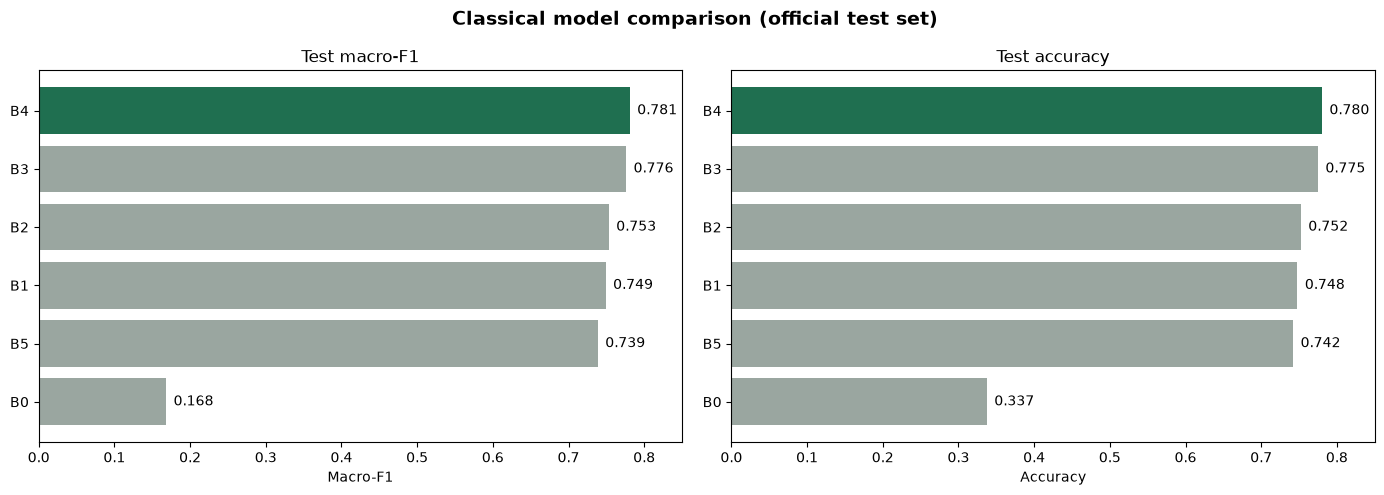

In [8]:
import matplotlib.pyplot as plt

# Visual summary: compare the recorded classical test results
viz_results = pd.DataFrame([
    {
        "id": row["id"],
        "name": row["name"],
        "test_accuracy": row["test"]["accuracy"],
        "test_macro_f1": row["test"]["macro_f1"],
    }
    for row in registry
]).sort_values("test_macro_f1", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#9aa6a0" if model_id != "B4" else "#1f6f50" for model_id in viz_results["id"]]
axes[0].barh(viz_results["id"], viz_results["test_macro_f1"], color=colors)
axes[0].set_title("Test macro-F1")
axes[0].set_xlabel("Macro-F1")
axes[0].set_xlim(0, 0.85)
for y, value in enumerate(viz_results["test_macro_f1"]):
    axes[0].text(value + 0.01, y, f"{value:.3f}", va="center")

axes[1].barh(viz_results["id"], viz_results["test_accuracy"], color=colors)
axes[1].set_title("Test accuracy")
axes[1].set_xlabel("Accuracy")
axes[1].set_xlim(0, 0.85)
for y, value in enumerate(viz_results["test_accuracy"]):
    axes[1].text(value + 0.01, y, f"{value:.3f}", va="center")

fig.suptitle("Classical model comparison (official test set)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
